In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [7]:
sick_dataset_path = "./dataset_sick.csv"


df_sick = pd.read_csv(sick_dataset_path, sep = ',')

pd.set_option("display.max_columns", None)
df_sick.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,Class
0,41.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.30,t,2.5,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.10,t,2.0,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,NaN,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative


In [8]:
df_sick['Class'].value_counts(normalize = True)

Class
negative    0.938759
sick        0.061241
Name: proportion, dtype: float64

In [9]:
df_sick.isnull().sum()

age                             1
sex                             0
on_thyroxine                    0
query_on_thyroxine              0
on_antithyroid_medication       0
sick                            0
pregnant                        0
thyroid_surgery                 0
I131_treatment                  0
query_hypothyroid               0
query_hyperthyroid              0
lithium                         0
goitre                          0
tumor                           0
hypopituitary                   0
psych                           0
TSH_measured                    0
TSH                           369
T3_measured                     0
T3                            769
TT4_measured                    0
TT4                           231
T4U_measured                    0
T4U                           387
FTI_measured                    0
FTI                           385
TBG_measured                    0
TBG                          3772
referral_source                 0
Class         

In [10]:
print(f"Number of samples: {df_sick.shape[0]}")
print(f"Number of attributes: {df_sick.shape[1]}")

Number of samples: 3772
Number of attributes: 30


In [11]:
df_sick.info()

<class 'pandas.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        3771 non-null   float64
 1   sex                        3772 non-null   str    
 2   on_thyroxine               3772 non-null   str    
 3   query_on_thyroxine         3772 non-null   str    
 4   on_antithyroid_medication  3772 non-null   str    
 5   sick                       3772 non-null   str    
 6   pregnant                   3772 non-null   str    
 7   thyroid_surgery            3772 non-null   str    
 8   I131_treatment             3772 non-null   str    
 9   query_hypothyroid          3772 non-null   str    
 10  query_hyperthyroid         3772 non-null   str    
 11  lithium                    3772 non-null   str    
 12  goitre                     3772 non-null   str    
 13  tumor                      3772 non-null   str    
 14  hyp

In [12]:
print(f"Duplicates: {df_sick.duplicated().sum()}")

Duplicates: 61


Text(0.5, 1.0, 'Distribution of Class')

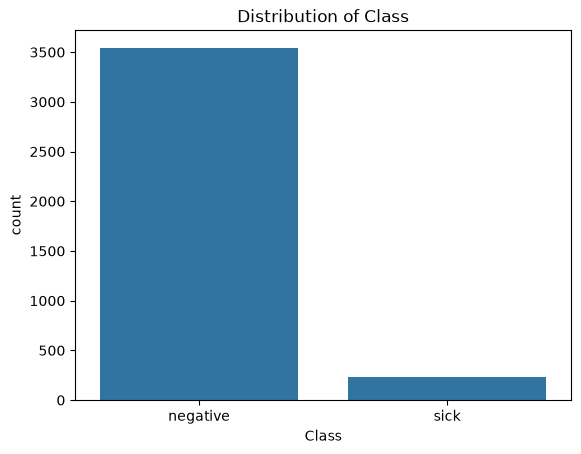

In [13]:
y_barchart = sns.countplot(data = df_sick, x = 'Class', stat = 'count')
y_barchart.set_title("Distribution of Class")

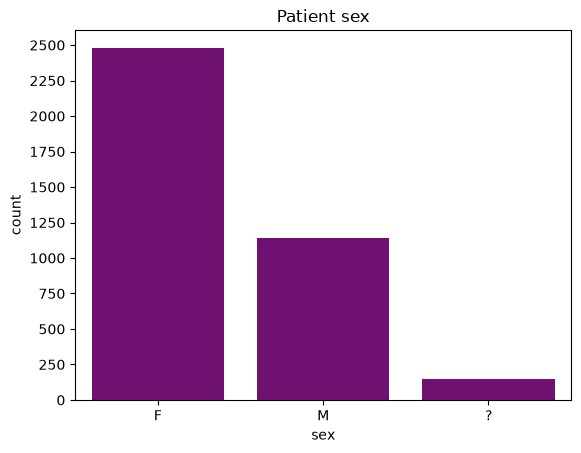

In [14]:
sex_barchart = sns.countplot(data = df_sick, x = 'sex', stat = 'count', color = 'purple')
sex_barchart.set_title('Patient sex')
sex_barchart.yaxis.set_major_locator(MultipleLocator(250))

Text(0.5, 1.0, 'Patient age')

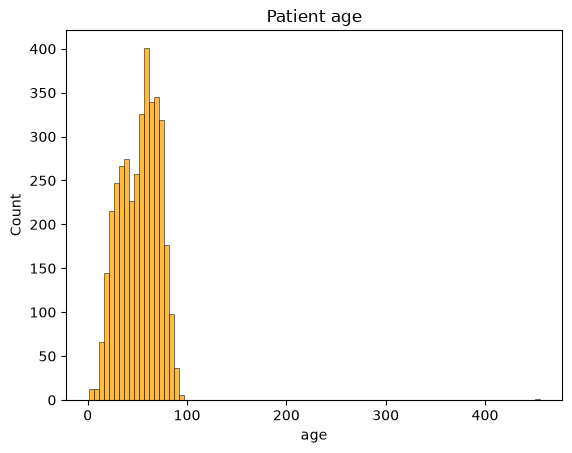

In [15]:
age_barchart = sns.histplot(data = df_sick, x = 'age', bins = 90, stat = 'count', color = 'orange')
age_barchart.set_title('Patient age')

Text(0.5, 1.0, 'TSH')

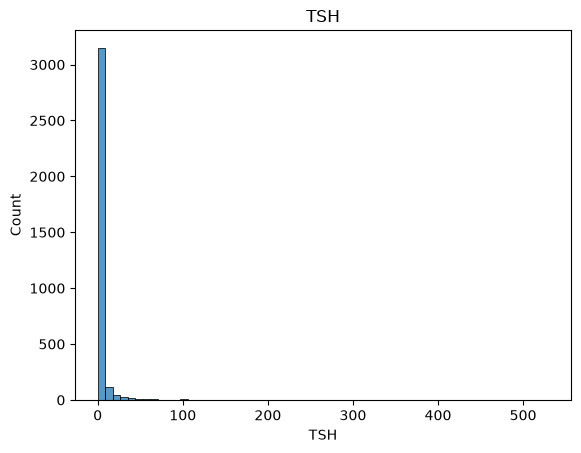

In [16]:
tsh_hist = sns.histplot(data = df_sick, x = 'TSH', stat = 'count', bins = 60)
tsh_hist.set_title('TSH')

Text(0.5, 1.0, 'T3')

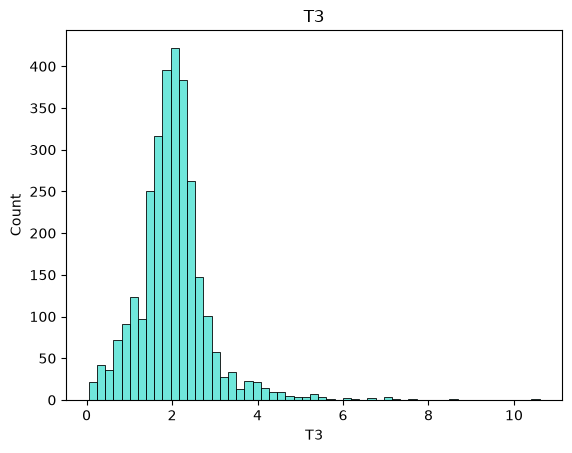

In [17]:
t3_hist = sns.histplot(data = df_sick, x = 'T3', stat = 'count', bins = 55, color = 'turquoise')
t3_hist.set_title('T3')

Text(0.5, 1.0, 'TT4')

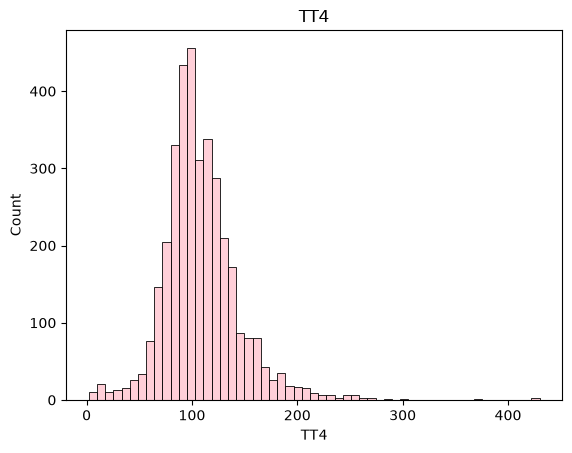

In [18]:
tt4_hist = sns.histplot(data = df_sick, x = 'TT4', stat = 'count', bins = 55, color = 'pink')
tt4_hist.set_title('TT4')

Text(0.5, 1.0, 'FTI')

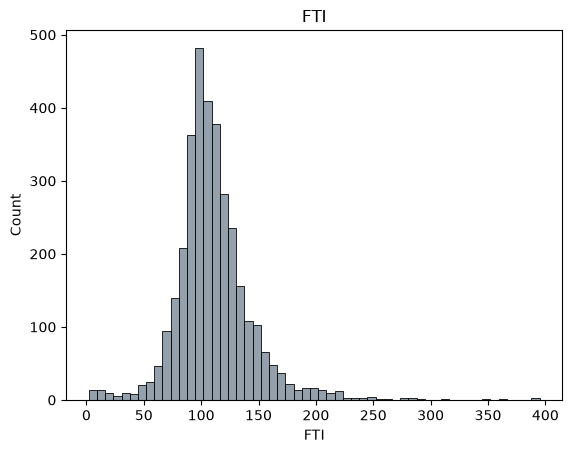

In [19]:
fti_hist = sns.histplot(data = df_sick, x = 'FTI', stat = 'count', bins = 55, color = 'slategrey')
fti_hist.set_title('FTI')

In [20]:
df_sick['TBG'].value_counts(normalize = True)*100

Series([], Name: proportion, dtype: float64)

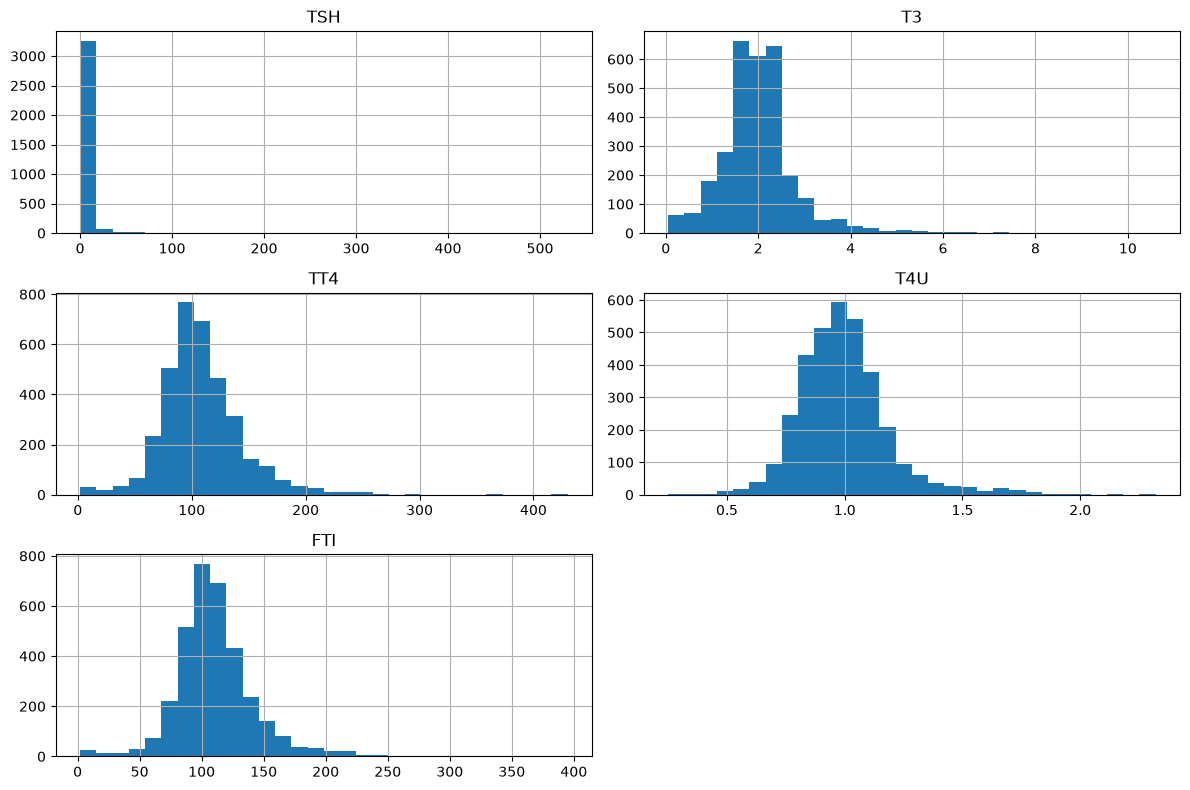

In [21]:
cols = ['TSH', 'T3', 'TT4', 'T4U', 'FTI']
df_sick[cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

Dataset 2: Churn

In [28]:
import pandas as pd
import seaborn as sns
import os
import certifi
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
import arff


In [32]:
with open("dataset_churn.arff") as f:
    d = arff.load(f)
df_churn = pd.DataFrame(d["data"], columns=[a[0] for a in d["attributes"]])
display(df_churn.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [33]:
df_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [34]:
df_churn.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,7043,2,2,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,7590-VHVEG,Male,0,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,5901,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,NaN,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,NaN,NaN,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,NaN,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,NaN,NaN,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [35]:
df_churn['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [36]:
df_churn.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [37]:
print(f"Duplicates: {df_churn.duplicated().sum()}")

Duplicates: 0


Text(0.5, 1.0, 'Distribution of Churn')

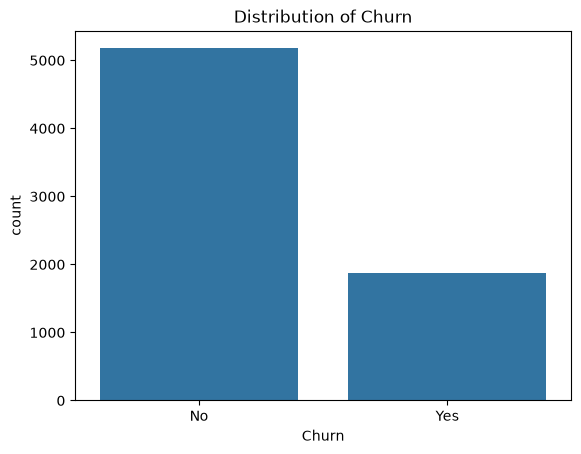

In [38]:
y_barchart = sns.countplot(data = df_churn, x = 'Churn', stat = 'count')
y_barchart.set_title("Distribution of Churn")

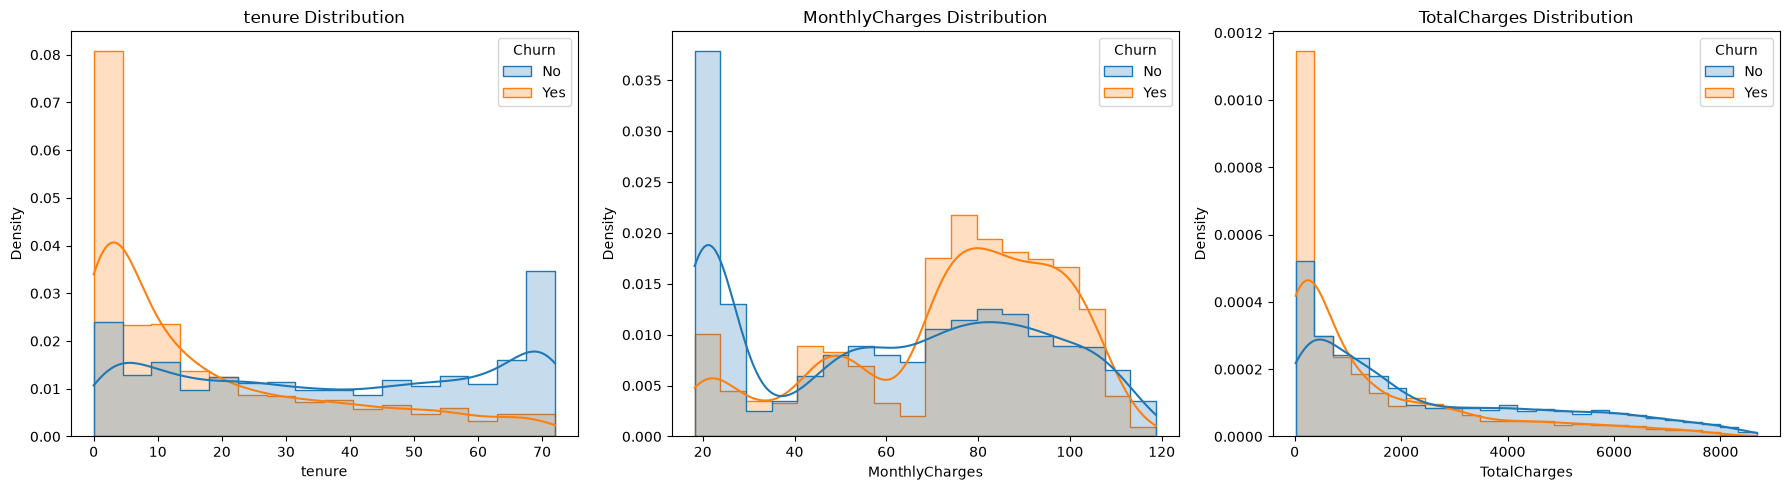

In [39]:

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, numeric_cols):
    sns.histplot(data=df_churn, x=column, hue='Churn', kde=True,
                 element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{column} Distribution')

plt.tight_layout()
plt.show()

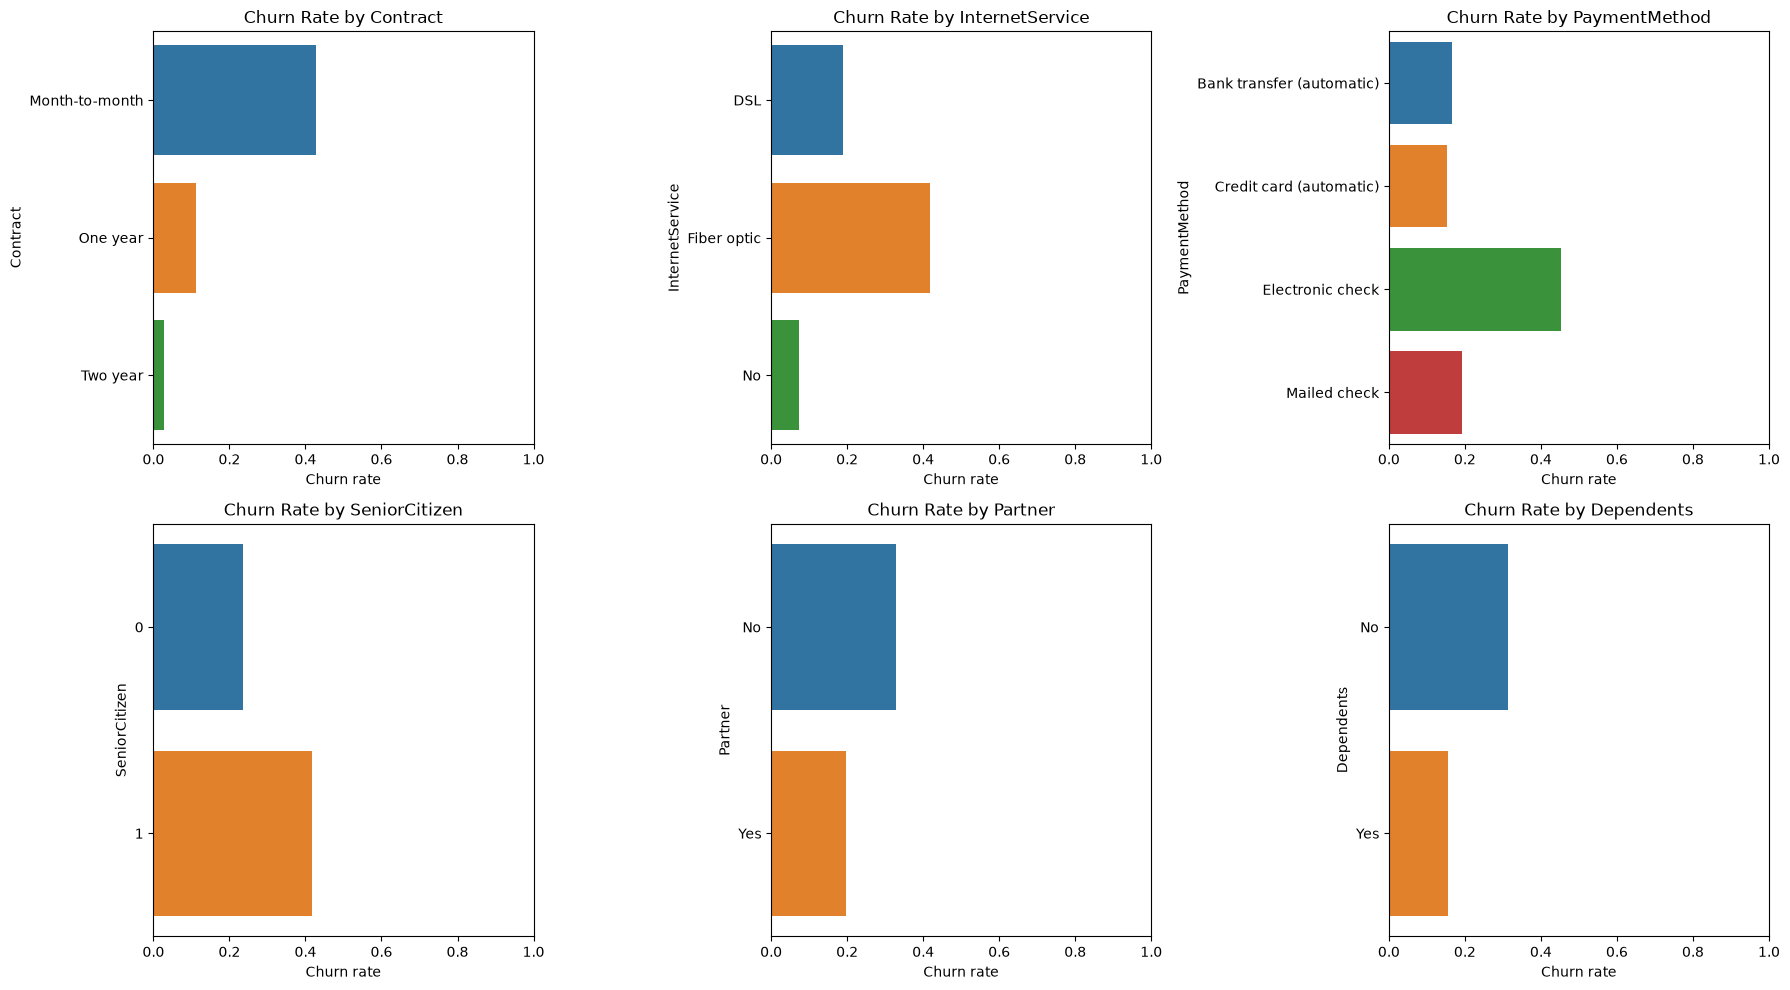

In [40]:
categorical_cols = ['Contract', 'InternetService', 'PaymentMethod',
                    'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, column in zip(axes.flat, categorical_cols):
    churn_rate = (
        df_churn.groupby(column, observed=False)['Churn']
        .apply(lambda values: (values == 'Yes').mean())
        .reset_index(name='ChurnRate')
    )
    sns.barplot(data=churn_rate, x='ChurnRate', y=column,
                hue=column, legend=False, ax=ax)
    ax.set_title(f'Churn Rate by {column}')
    ax.set_xlabel('Churn rate')
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

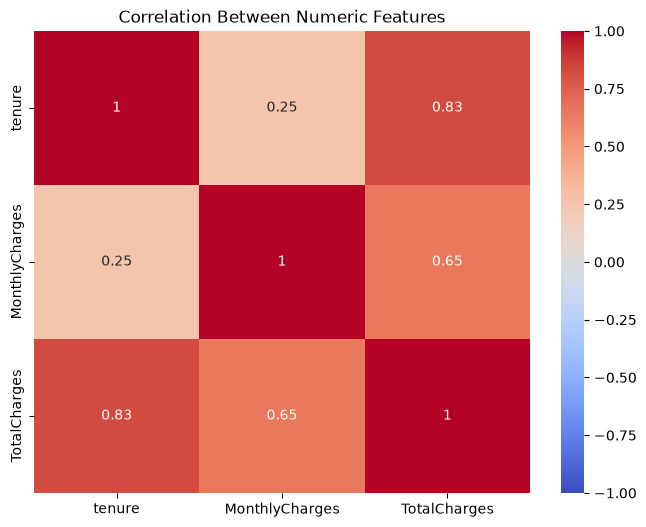

In [41]:
plt.figure(figsize=(8, 6))
correlation = df_churn[numeric_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Features')
plt.show()

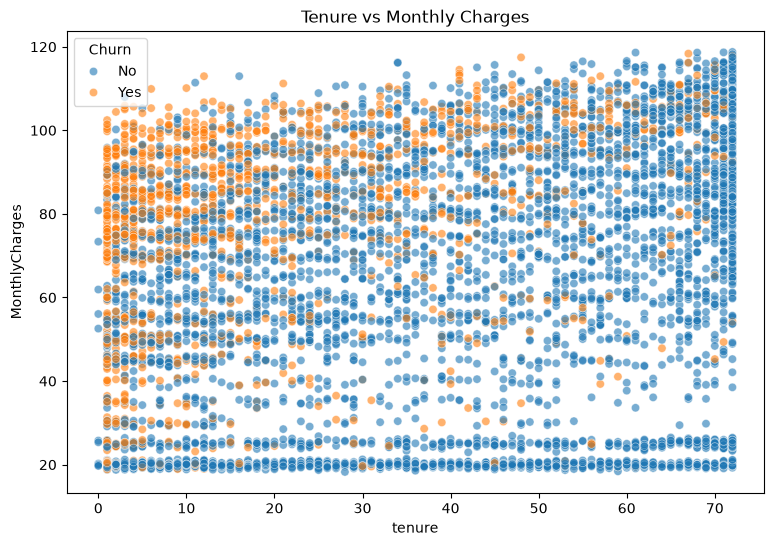

In [42]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_churn,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    alpha=0.6
)
plt.title('Tenure vs Monthly Charges')
plt.show()